In [69]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import plot_tree
from sklearn.tree import export_text

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.metrics import r2_score
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

import matplotlib.pyplot as plt

In [70]:
df = pd.read_csv("C:/Users/kayce/Downloads/archive (2)/dataset_2.csv")
print(df.head())
print(df.info())
df = df.dropna()
print(df.isnull().sum())

     Area_SqFt  Rooms  Build_Year Location       Street_Type      Furnishing  \
0  2473.192784    4.0        1992   Jaipur  Residential Lane       Furnished   
1  2353.472711    4.0        2006   Indore       Corner Plot     Unfurnished   
2  2212.222005    3.0        2012   Jaipur    Highway Facing  Semi-Furnished   
3  2823.886596    6.0        1993  Lucknow         Main Road     Unfurnished   
4  1869.648721    5.0        2012   Jaipur       Corner Plot  Semi-Furnished   

  Property_Type Has_Pool     Price  
0     Apartment       No  568486.0  
1     Apartment      Yes  577214.0  
2        Duplex       No  581300.0  
3         Villa      Yes  794614.0  
4     Apartment       No  493086.0  
<class 'pandas.DataFrame'>
RangeIndex: 1124 entries, 0 to 1123
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Area_SqFt      1091 non-null   float64
 1   Rooms          1091 non-null   float64
 2   Build_Year     1124 n

In [71]:
reference_year = df["Build_Year"].max()
df["Age"] = reference_year - df["Build_Year"]


def age_category(age):
    if age <= 10:
        return "New"
    elif age <= 25:
        return "Moderate"
    else:
        return "Old"

df["Age_Category"] = df["Age"].apply(age_category)

df.drop(columns=["Build_Year", "Age"], inplace=True)

X = df.drop("Price", axis=1)
y = df["Price"]

categorical_columns = [
    "Age_Category",
    "Location",
    "Street_Type",
    "Furnishing",
    "Property_Type",
    "Has_Pool"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
    ],
    remainder="passthrough"
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", DecisionTreeRegressor(random_state=42))
])

model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Area_SqFt','Rooms','Location',...,'Property_Type','Has_Pool', 'Age_Category']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis c

In [72]:

# Get the trained decision tree
tree = model.named_steps["regressor"]

# Get the feature names AFTER preprocessing
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

feature_names = [
    name.replace("cat__", "")
        .replace("remainder__", "")
    for name in feature_names
]

print(feature_names)

['Age_Category_Moderate', 'Age_Category_New', 'Age_Category_Old', 'Location_Delhi', 'Location_Gurugram', 'Location_Indore', 'Location_Jaipur', 'Location_Kanpur', 'Location_Lucknow', 'Location_Noida', 'Location_Prayagraj', 'Street_Type_Corner Plot', 'Street_Type_Gated Society', 'Street_Type_Highway Facing', 'Street_Type_Main Road', 'Street_Type_Residential Lane', 'Furnishing_Furnished', 'Furnishing_Semi-Furnished', 'Furnishing_Unfurnished', 'Property_Type_Apartment', 'Property_Type_Duplex', 'Property_Type_Independent House', 'Property_Type_Villa', 'Has_Pool_No', 'Has_Pool_Yes', 'Area_SqFt', 'Rooms']


In [73]:
y_pred = model.predict(X_test)

In [74]:
print("R² Score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

R² Score: 0.7981555948025749
MAE: 46091.457796116505
MSE: 3493808123.6538253
RMSE: 59108.44375936339


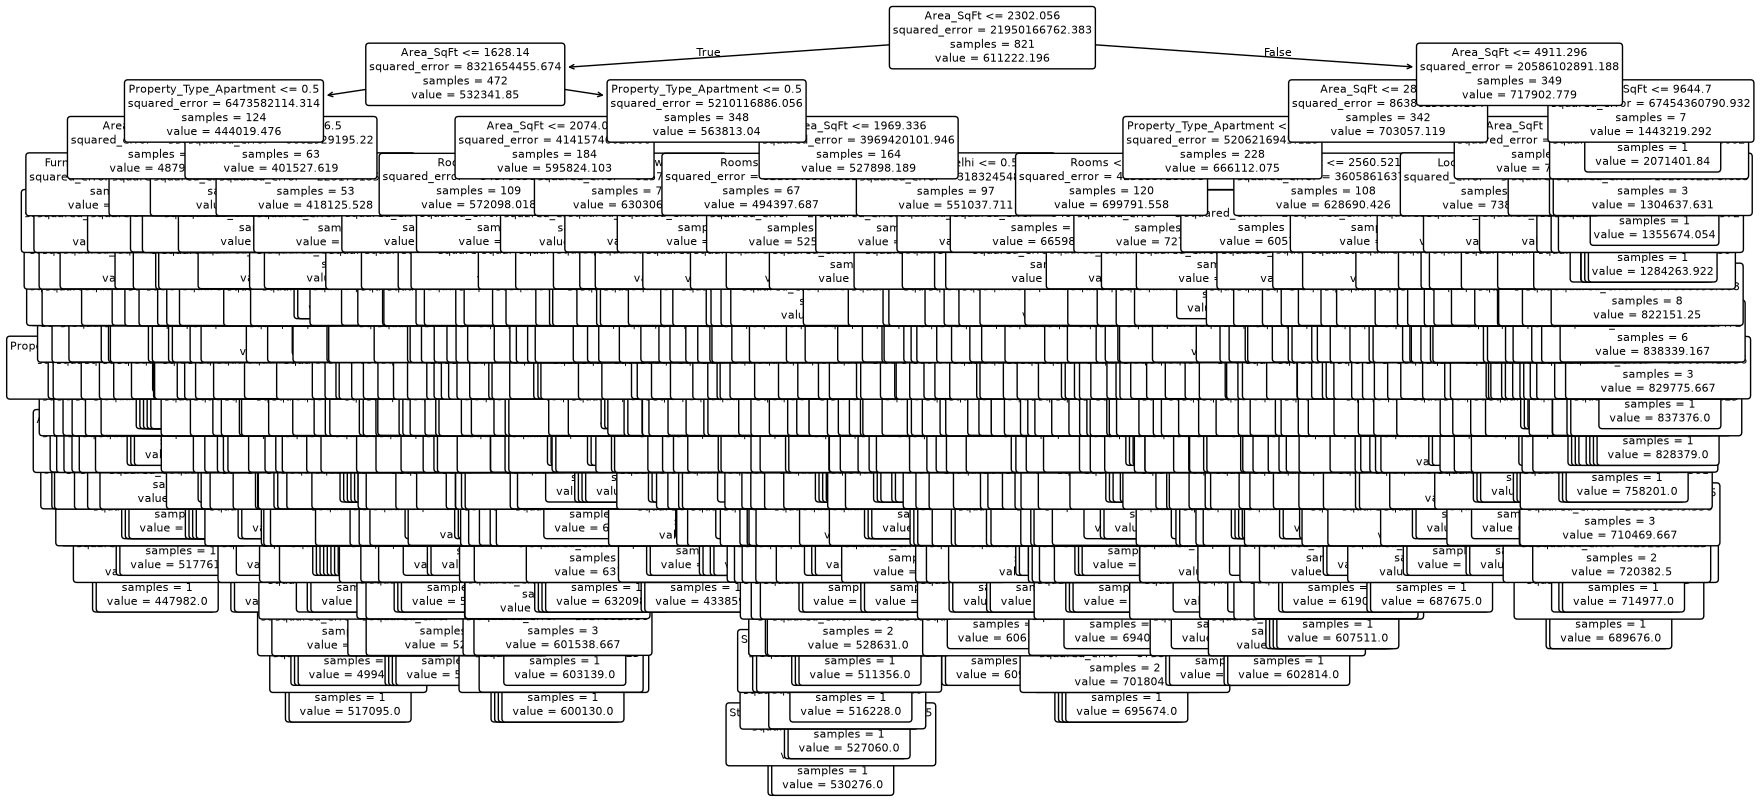

In [75]:
tree = model.named_steps["regressor"]

plt.figure(figsize=(20,10))

plot_tree(
    tree,
    feature_names=feature_names,
    rounded=True,
    fontsize=8
)

plt.show()

['Age_Category_Moderate', 'Age_Category_New', 'Age_Category_Old', 'Location_Delhi', 'Location_Gurugram', 'Location_Indore', 'Location_Jaipur', 'Location_Kanpur', 'Location_Lucknow', 'Location_Noida', 'Location_Prayagraj', 'Street_Type_Corner Plot', 'Street_Type_Gated Society', 'Street_Type_Highway Facing', 'Street_Type_Main Road', 'Street_Type_Residential Lane', 'Furnishing_Furnished', 'Furnishing_Semi-Furnished', 'Furnishing_Unfurnished', 'Property_Type_Apartment', 'Property_Type_Duplex', 'Property_Type_Independent House', 'Property_Type_Villa', 'Has_Pool_No', 'Has_Pool_Yes', 'Area_SqFt', 'Rooms']


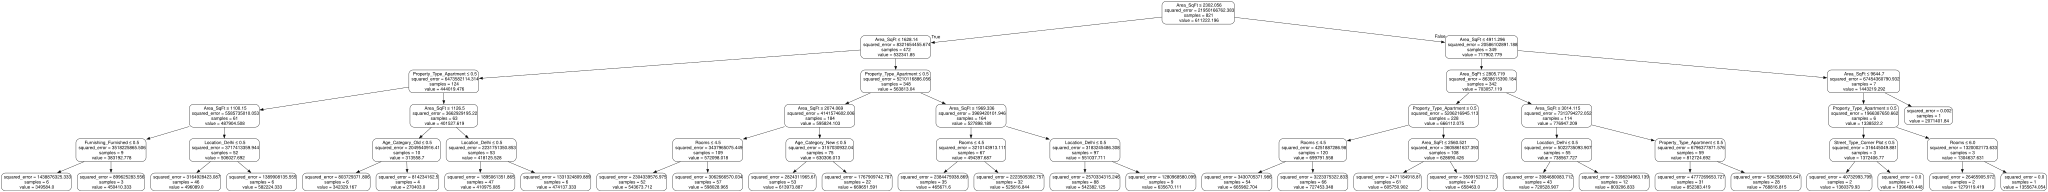

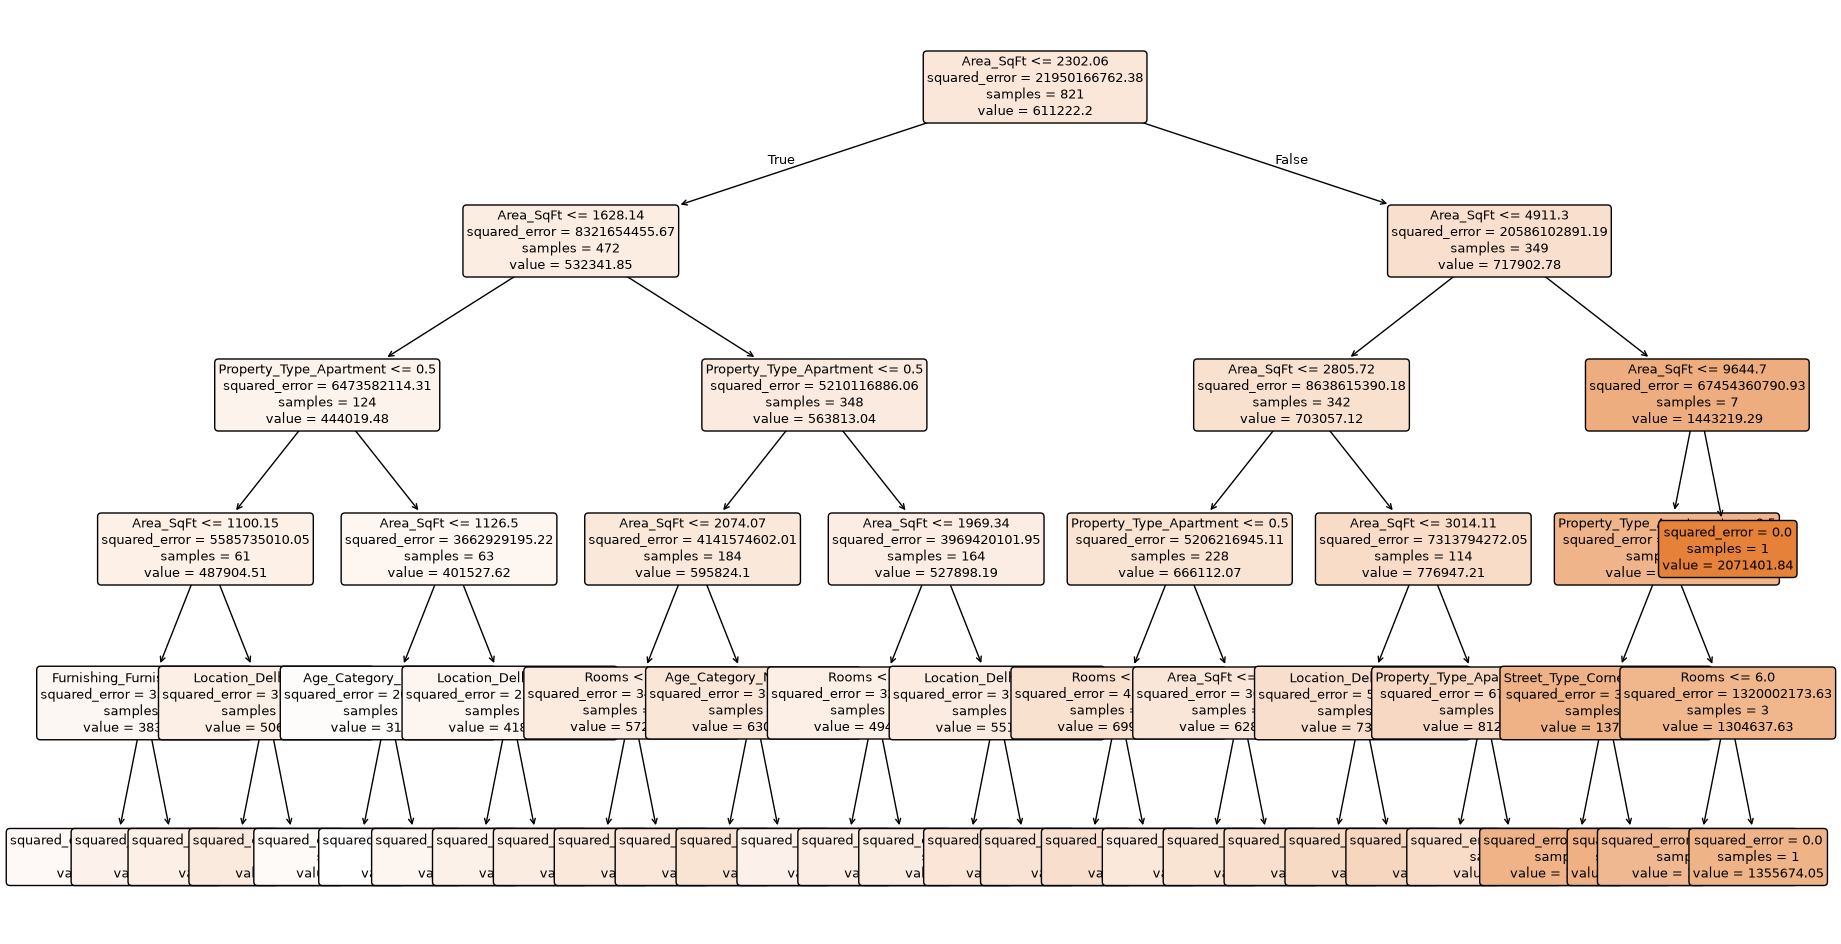

In [76]:
# Pruning the tree
from sklearn.tree import export_graphviz
import graphviz
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", DecisionTreeRegressor(
        max_depth=5,
        random_state=42
    ))
])

model.fit(X_train, y_train)

# Get the trained decision tree
tree = model.named_steps["regressor"]

# Get the feature names AFTER preprocessing
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

feature_names = [
    name.replace("cat__", "")
        .replace("remainder__", "")
    for name in feature_names
]

print(feature_names)

plt.figure(figsize=(22,12))

plot_tree(
    tree,
    feature_names=feature_names,
    filled=True,
    rounded=True,
    fontsize=9,
    precision=2
)



tree = model.named_steps["regressor"]

dot_data = export_graphviz(
    tree,
    feature_names=feature_names,
    rounded=True,
    special_characters=True
)

graph = graphviz.Source(dot_data)
graph.render("HousePriceDecisionTree", format="pdf")
graph



In [77]:
rules = export_text(tree)

print(rules)

|--- feature_25 <= 2302.06
|   |--- feature_25 <= 1628.14
|   |   |--- feature_19 <= 0.50
|   |   |   |--- feature_25 <= 1100.15
|   |   |   |   |--- feature_16 <= 0.50
|   |   |   |   |   |--- value: [349584.00]
|   |   |   |   |--- feature_16 >  0.50
|   |   |   |   |   |--- value: [450410.33]
|   |   |   |--- feature_25 >  1100.15
|   |   |   |   |--- feature_3 <= 0.50
|   |   |   |   |   |--- value: [496089.00]
|   |   |   |   |--- feature_3 >  0.50
|   |   |   |   |   |--- value: [582224.33]
|   |   |--- feature_19 >  0.50
|   |   |   |--- feature_25 <= 1126.50
|   |   |   |   |--- feature_2 <= 0.50
|   |   |   |   |   |--- value: [342329.17]
|   |   |   |   |--- feature_2 >  0.50
|   |   |   |   |   |--- value: [270403.00]
|   |   |   |--- feature_25 >  1126.50
|   |   |   |   |--- feature_3 <= 0.50
|   |   |   |   |   |--- value: [410975.09]
|   |   |   |   |--- feature_3 >  0.50
|   |   |   |   |   |--- value: [474137.33]
|   |--- feature_25 >  1628.14
|   |   |--- feature_19 <

overfitting

doesnt work the way humans think, buh only according to structure of training dataset


Although features such as the number of rooms, furnishing status, property age, and the presence 
of a swimming pool are expected to influence house prices in real-world markets, the trained 
decision tree primarily selected Area_SqFt and Property_Type for its upper-level splits. 
This indicates that, within this dataset, these variables provided the greatest reduction 
in prediction error. Other variables may still contribute to predictions but had less 
influence than the selected features.